# 02 - Variable Selection and Data Preprocessing

## Objective

The purpose of this notebook is to prepare a high-quality analytical dataset for the Global Health Policy Decision Intelligence Framework.

The notebook performs the following tasks:

- Select relevant global health indicators based on the study objectives.
- Clean and organize the dataset.
- Reshape the data from long format to wide format.
- Assess and manage missing data.
- Examine data quality and validate indicator values.
- Perform exploratory data analysis (EDA), including distributions and correlations.
- Produce a clean, analysis-ready dataset for machine learning.

The processed dataset generated in this notebook will be used for:

- Machine Learning modeling
- Explainable AI (Feature Importance)
- Development of the Policy Priority Index
- SQL Database Development
- Power BI Dashboard
- Policy Decision Support Framework

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("C:\\Users\\786\\Desktop\\document\\Global Health Policy Decision Intelligence\\notebooks\\clean_health_data.csv")

In [3]:
df.head()

,Series Name,Series Code,Country Name,Country Code,Year,Value
0,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,Afghanistan,AFG,1960,140.598
1,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,Burkina Faso,BFA,1960,135.470
2,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,Burundi,BDI,1960,95.936
3,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,Central African Republic,CAF,1960,169.818
4,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,Chad,TCD,1960,195.419


In [4]:
variables = pd.DataFrame({
    "Indicator": sorted(df["Series Name"].unique())
})
variables.head(20)

,Indicator
0,AIDS estimated deaths (UNAIDS estimates)
1,ARI treatment (% of children under 5 taken to ...
2,"Adolescent fertility rate (births per 1,000 wo..."
3,Adults (ages 15+) and children (0-14 years) li...
4,Adults (ages 15+) and children (ages 0-14) new...
5,Adults (ages 15+) living with HIV
6,Adults (ages 15-49) newly infected with HIV
7,"Age at first marriage, female"
8,"Age at first marriage, male"
9,Age dependency ratio (% of working-age populat...


In [5]:
variables["Category"] = ""
variables["Role"] = ""
variables["Keep"] = ""
variables["Reason"] = ""

In [6]:
def categorize_indicator(indicator):
    indicator = indicator.lower()

    if any(x in indicator for x in ["life expectancy", "mortality", "death", "stillbirth"]):
        return "Health Outcomes"

    elif any(x in indicator for x in ["health expenditure", "out-of-pocket", "government health", "external health"]):
        return "Health Financing"

    elif any(x in indicator for x in ["physicians", "nurses", "hospital beds", "community health workers", "specialist surgical workforce"]):
        return "Health Workforce"

    elif any(x in indicator for x in ["hiv", "tuberculosis", "malaria", "aids"]):
        return "Disease Burden"

    elif any(x in indicator for x in ["immunization", "antenatal", "prenatal", "postnatal", "birth", "contraceptive"]):
        return "Health Services"

    elif any(x in indicator for x in ["water", "sanitation", "handwashing", "open defecation"]):
        return "Water & Sanitation"

    elif any(x in indicator for x in ["stunting", "wasting", "underweight", "breastfeeding", "nutrition", "undernourishment", "anemia"]):
        return "Nutrition"

    elif any(x in indicator for x in ["population", "fertility", "dependency", "urban", "rural", "migration"]):
        return "Demographics"

    elif any(x in indicator for x in ["gni", "literacy", "poverty", "education", "human capital", "school", "unemployment", "labor force"]):
        return "Socioeconomic"

    elif any(x in indicator for x in ["tobacco", "alcohol", "hypertension", "diabetes", "overweight"]):
        return "Risk Factors"

    else:
        return "Other"

In [7]:
variables["Category"] = variables["Indicator"].apply(categorize_indicator)
variables.head(26)

,Indicator,Category,Role,Keep,Reason
0,AIDS estimated deaths (UNAIDS estimates),Health Outcomes,,,
1,ARI treatment (% of children under 5 taken to ...,Other,,,
2,"Adolescent fertility rate (births per 1,000 wo...",Health Services,,,
3,Adults (ages 15+) and children (0-14 years) li...,Disease Burden,,,
4,Adults (ages 15+) and children (ages 0-14) new...,Disease Burden,,,
5,Adults (ages 15+) living with HIV,Disease Burden,,,
6,Adults (ages 15-49) newly infected with HIV,Disease Burden,,,
7,"Age at first marriage, female",Other,,,
8,"Age at first marriage, male",Other,,,
9,Age dependency ratio (% of working-age populat...,Demographics,,,


In [8]:
variables["Category"].value_counts()

Category
Demographics          160
Health Outcomes        67
Other                  46
Socioeconomic          36
Health Financing       30
Health Services        29
Disease Burden         29
Nutrition              21
Risk Factors           21
Water & Sanitation     18
Health Workforce        5
Name: count, dtype: int64

In [9]:
def assign_role(indicator):
    indicator = indicator.lower()

    # Main prediction targets
    if "life expectancy at birth, total" in indicator:
        return "Target"

    elif "maternal mortality ratio (modeled estimate" in indicator:
        return "Target"

    elif "mortality rate, under-5" in indicator and "female" not in indicator and "male" not in indicator:
        return "Target"

    # Everything else is initially a feature
    else:
        return "Feature"

variables["Role"] = variables["Indicator"].apply(assign_role)

In [10]:
variables[variables["Role"] == "Target"]

,Indicator,Category,Role,Keep,Reason
153,"Life expectancy at birth, total (years)",Health Outcomes,Target,,
164,"Maternal mortality ratio (modeled estimate, pe...",Health Outcomes,Target,,
187,"Mortality rate, under-5 (per 1,000)",Health Outcomes,Target,,


In [11]:
variables["Keep"] = "Review"

In [12]:
variables[variables["Category"]=="Health Financing"]

,Indicator,Category,Role,Keep,Reason
68,Capital health expenditure (% of GDP),Health Financing,Feature,Review,
99,Current health expenditure (% of GDP),Health Financing,Feature,Review,
100,Current health expenditure per capita (current...,Health Financing,Feature,Review,
101,"Current health expenditure per capita, PPP (cu...",Health Financing,Feature,Review,
108,Domestic general government health expenditure...,Health Financing,Feature,Review,
109,Domestic general government health expenditure...,Health Financing,Feature,Review,
110,Domestic general government health expenditure...,Health Financing,Feature,Review,
111,Domestic general government health expenditure...,Health Financing,Feature,Review,
112,Domestic general government health expenditure...,Health Financing,Feature,Review,
113,Domestic private health expenditure (% of curr...,Health Financing,Feature,Review,


In [13]:
keep_financing = [
    "Current health expenditure (% of GDP)",
    "Current health expenditure per capita (current US$)",
    "Current health expenditure per capita, PPP (current international $)",
    "Domestic general government health expenditure (% of GDP)",
    "Domestic general government health expenditure (% of current health expenditure)",
    "Domestic general government health expenditure (% of general government expenditure)",
    "Domestic private health expenditure (% of current health expenditure)",
    "External health expenditure (% of current health expenditure)",
    "External health expenditure channeled through government (% of external health expenditure)",
    "Out-of-pocket expenditure (% of current health expenditure)",
    "Proportion of population pushed below the $3.65 ($ 2017 PPP) poverty line by out-of-pocket health care expenditure (%)",
    "Proportion of population spending more than 10% of household consumption or income on out-of-pocket health care expenditure (%)",
    "Proportion of population spending more than 25% of household consumption or income on out-of-pocket health care expenditure (%)"
]

In [14]:
variables.loc[
    variables["Category"] == "Health Financing",
    "Keep"
] = "No"

In [15]:
variables.loc[
    variables["Indicator"].isin(keep_financing),
    "Keep"
] = "Yes"

In [16]:
variables[variables["Category"] == "Health Financing"][
    ["Indicator", "Keep"]
].sort_values("Keep", ascending=False)

,Indicator,Keep
405,Proportion of population spending more than 25...,Yes
99,Current health expenditure (% of GDP),Yes
100,Current health expenditure per capita (current...,Yes
101,"Current health expenditure per capita, PPP (cu...",Yes
108,Domestic general government health expenditure...,Yes
109,Domestic general government health expenditure...,Yes
110,Domestic general government health expenditure...,Yes
404,Proportion of population spending more than 10...,Yes
113,Domestic private health expenditure (% of curr...,Yes
396,Proportion of population pushed below the $3.6...,Yes


In [17]:
variables.to_csv("selected_variables.csv", index=False)

In [18]:
variables[variables["Category"] == "Health Workforce"][["Indicator", "Keep"]]

,Indicator,Keep
77,"Community health workers (per 1,000 people)",Review
124,"Hospital beds (per 1,000 people)",Review
219,"Nurses and midwives (per 1,000 people)",Review
241,"Physicians (per 1,000 people)",Review
430,"Specialist surgical workforce (per 100,000 pop...",Review


In [19]:
keep_workforce = [
    "Community health workers (per 1,000 people)",
    "Hospital beds (per 1,000 people)",
    "Nurses and midwives (per 1,000 people)",
    "Physicians (per 1,000 people)",
    "Specialist surgical workforce (per 100,000 population)"
]

In [20]:
variables.loc[
    variables["Category"] == "Health Workforce",
    "Keep"
] = "No"

In [21]:
variables.loc[
    variables["Indicator"].isin(keep_workforce),
    "Keep"
] = "Yes"

In [22]:
variables[variables["Category"] == "Health Workforce"][["Indicator", "Keep"]]

,Indicator,Keep
77,"Community health workers (per 1,000 people)",Yes
124,"Hospital beds (per 1,000 people)",Yes
219,"Nurses and midwives (per 1,000 people)",Yes
241,"Physicians (per 1,000 people)",Yes
430,"Specialist surgical workforce (per 100,000 pop...",Yes


In [23]:
variables[variables["Category"] == "Health Services"][["Indicator", "Keep"]]

,Indicator,Keep
2,"Adolescent fertility rate (births per 1,000 wo...",Review
66,"Birth rate, crude (per 1,000 people)",Review
67,Births attended by skilled health staff (% of ...,Review
78,Completeness of birth registration (%),Review
79,"Completeness of birth registration, female (%)",Review
80,"Completeness of birth registration, male (%)",Review
81,"Completeness of birth registration, rural (%)",Review
82,"Completeness of birth registration, urban (%)",Review
93,"Contraceptive prevalence, any method (% of all...",Review
94,"Contraceptive prevalence, any method (% of mar...",Review


In [24]:
keep_services = [
    "Adolescent fertility rate (births per 1,000 women ages 15-19)",
    "Births attended by skilled health staff (% of total)",
    "Completeness of birth registration (%)",
    "Contraceptive prevalence, any modern method (% of all women ages 15-49)",
    "Fertility rate, total (births per woman)",
    "Immunization, DPT (% of children ages 12-23 months)",
    "Immunization, Pol3 (% of one-year-old children)",
    "Immunization, measles (% of children ages 12-23 months)",
    "Low-birthweight babies (% of births)",
    "Postnatal care coverage (% mothers)",
    "Pregnant women receiving prenatal care of at least four visits (% of pregnant women)",
    "Prevalence of syphilis (% of women attending antenatal care)"
]

In [25]:
variables.loc[
    variables["Category"] == "Health Services",
    "Keep"
] = "No"

In [26]:
variables.loc[
    variables["Indicator"].isin(keep_services),
    "Keep"
] = "Yes"

In [27]:
variables[variables["Category"] == "Health Services"][["Indicator", "Keep"]]

,Indicator,Keep
2,"Adolescent fertility rate (births per 1,000 wo...",Yes
66,"Birth rate, crude (per 1,000 people)",No
67,Births attended by skilled health staff (% of ...,Yes
78,Completeness of birth registration (%),Yes
79,"Completeness of birth registration, female (%)",No
80,"Completeness of birth registration, male (%)",No
81,"Completeness of birth registration, rural (%)",No
82,"Completeness of birth registration, urban (%)",No
93,"Contraceptive prevalence, any method (% of all...",No
94,"Contraceptive prevalence, any method (% of mar...",No


In [28]:
variables[variables["Category"] == "Disease Burden"][["Indicator", "Keep"]]

,Indicator,Keep
3,Adults (ages 15+) and children (0-14 years) li...,Review
4,Adults (ages 15+) and children (ages 0-14) new...,Review
5,Adults (ages 15+) living with HIV,Review
6,Adults (ages 15-49) newly infected with HIV,Review
64,Antiretroviral therapy coverage (% of people l...,Review
65,Antiretroviral therapy coverage for PMTCT (% o...,Review
73,Children (0-14) living with HIV,Review
74,Children (ages 0-14) newly infected with HIV,Review
75,Children orphaned by HIV/AIDS,Review
76,Children with fever receiving antimalarial dru...,Review


In [29]:
keep_disease = [
    "Adults (ages 15+) and children (0-14 years) living with HIV",
    "Adults (ages 15+) and children (ages 0-14) newly infected with HIV",
    "Antiretroviral therapy coverage (% of people living with HIV)",
    "Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV)",
    "Children orphaned by HIV/AIDS",
    "Children with fever receiving antimalarial drugs (% of children under age 5 with fever)",
    "Incidence of HIV, all (per 1,000 uninfected population)",
    "Incidence of malaria (per 1,000 population at risk)",
    "Incidence of tuberculosis (per 100,000 people)",
    "Intermittent preventive treatment (IPT) of malaria in pregnancy (% of pregnant women)",
    "Prevalence of HIV, total (% of population ages 15-49)",
    "Tuberculosis case detection rate (%, all forms)",
    "Tuberculosis treatment success rate (% of new cases)"
]

In [30]:
variables.loc[
    variables["Category"] == "Disease Burden",
    "Keep"
] = "No"

In [31]:
variables.loc[
    variables["Indicator"].isin(keep_disease),
    "Keep"
] = "Yes"

In [32]:
variables[variables["Category"] == "Disease Burden"][["Indicator", "Keep"]]

,Indicator,Keep
3,Adults (ages 15+) and children (0-14 years) li...,Yes
4,Adults (ages 15+) and children (ages 0-14) new...,Yes
5,Adults (ages 15+) living with HIV,No
6,Adults (ages 15-49) newly infected with HIV,No
64,Antiretroviral therapy coverage (% of people l...,Yes
65,Antiretroviral therapy coverage for PMTCT (% o...,Yes
73,Children (0-14) living with HIV,No
74,Children (ages 0-14) newly infected with HIV,No
75,Children orphaned by HIV/AIDS,Yes
76,Children with fever receiving antimalarial dru...,Yes


In [33]:
variables[variables["Category"] == "Nutrition"][["Indicator", "Keep"]]

,Indicator,Keep
116,Exclusive breastfeeding (% of children under 6...,Review
341,Prevalence of anemia among children (% of chil...,Review
342,Prevalence of anemia among non-pregnant women ...,Review
343,Prevalence of anemia among pregnant women (%),Review
344,Prevalence of anemia among women of reproducti...,Review
360,"Prevalence of severe wasting, weight for heigh...",Review
361,"Prevalence of severe wasting, weight for heigh...",Review
362,"Prevalence of severe wasting, weight for heigh...",Review
363,"Prevalence of stunting, height for age (% of c...",Review
364,"Prevalence of stunting, height for age (modele...",Review


In [34]:
keep_nutrition = [
    "Exclusive breastfeeding (% of children under 6 months)",
    "Prevalence of anemia among children (% of children ages 6-59 months)",
    "Prevalence of anemia among pregnant women (%)",
    "Prevalence of anemia among women of reproductive age (% of women ages 15-49)",
    "Prevalence of severe wasting, weight for height (% of children under 5)",
    "Prevalence of stunting, height for age (% of children under 5)",
    "Prevalence of undernourishment (% of population)",
    "Prevalence of underweight, weight for age (% of children under 5)",
    "Prevalence of wasting, weight for height (% of children under 5)"
]

In [35]:
variables.loc[
    variables["Category"] == "Nutrition",
    "Keep"
] = "No"

In [36]:
variables.loc[
    variables["Indicator"].isin(keep_nutrition),
    "Keep"
] = "Yes"

In [37]:
variables[variables["Category"] == "Nutrition"][["Indicator", "Keep"]]

,Indicator,Keep
116,Exclusive breastfeeding (% of children under 6...,Yes
341,Prevalence of anemia among children (% of chil...,Yes
342,Prevalence of anemia among non-pregnant women ...,No
343,Prevalence of anemia among pregnant women (%),Yes
344,Prevalence of anemia among women of reproducti...,Yes
360,"Prevalence of severe wasting, weight for heigh...",Yes
361,"Prevalence of severe wasting, weight for heigh...",No
362,"Prevalence of severe wasting, weight for heigh...",No
363,"Prevalence of stunting, height for age (% of c...",Yes
364,"Prevalence of stunting, height for age (modele...",No


In [38]:
variables[variables["Category"] == "Risk Factors"][["Indicator", "Keep"]]

,Indicator,Keep
345,Prevalence of current tobacco use (% of adults),Review
346,"Prevalence of current tobacco use, females (% ...",Review
347,"Prevalence of current tobacco use, males (% of...",Review
348,Prevalence of hypertension (% of adults ages 3...,Review
349,"Prevalence of hypertension, female (% of femal...",Review
350,"Prevalence of hypertension, male (% of male ad...",Review
351,Prevalence of overweight (% of adults),Review
352,Prevalence of overweight (% of children under 5),Review
353,"Prevalence of overweight (modeled estimate, % ...",Review
354,"Prevalence of overweight, female (% of childre...",Review


In [39]:
keep_risk = [
    "Prevalence of current tobacco use (% of adults)",
    "Prevalence of hypertension (% of adults ages 30-79)",
    "Prevalence of overweight (% of adults)",
    "Prevalence of overweight (% of children under 5)",
    "Total alcohol consumption per capita (liters of pure alcohol, projected estimates, 15+ years of age)",
    "Treatment for hypertension (% of adults ages 30-79 with hypertension)"
]

In [40]:
variables.loc[
    variables["Category"] == "Risk Factors",
    "Keep"
] = "No"

In [41]:
variables.loc[
    variables["Indicator"].isin(keep_risk),
    "Keep"
] = "Yes"

In [42]:
variables[variables["Category"] == "Risk Factors"][["Indicator", "Keep"]]

,Indicator,Keep
345,Prevalence of current tobacco use (% of adults),Yes
346,"Prevalence of current tobacco use, females (% ...",No
347,"Prevalence of current tobacco use, males (% of...",No
348,Prevalence of hypertension (% of adults ages 3...,Yes
349,"Prevalence of hypertension, female (% of femal...",No
350,"Prevalence of hypertension, male (% of male ad...",No
351,Prevalence of overweight (% of adults),Yes
352,Prevalence of overweight (% of children under 5),Yes
353,"Prevalence of overweight (modeled estimate, % ...",No
354,"Prevalence of overweight, female (% of childre...",No


In [43]:
variables[variables["Category"] == "Water & Sanitation"][["Indicator", "Keep"]]

,Indicator,Keep
223,People practicing open defecation (% of popula...,Review
224,"People practicing open defecation, rural (% of...",Review
225,"People practicing open defecation, urban (% of...",Review
226,People using at least basic drinking water ser...,Review
227,People using at least basic drinking water ser...,Review
228,People using at least basic drinking water ser...,Review
229,People using at least basic sanitation service...,Review
230,People using at least basic sanitation service...,Review
231,People using at least basic sanitation service...,Review
232,People using safely managed drinking water ser...,Review


In [44]:
keep_water = [
    "People practicing open defecation (% of population)",
    "People using at least basic drinking water services (% of population)",
    "People using at least basic sanitation services (% of population)",
    "People using safely managed drinking water services (% of population)",
    "People using safely managed sanitation services (% of population)",
    "People with basic handwashing facilities including soap and water (% of population)"
]

In [45]:
variables.loc[
    variables["Category"] == "Water & Sanitation",
    "Keep"
] = "No"

In [46]:
variables.loc[
    variables["Indicator"].isin(keep_water),
    "Keep"
] = "Yes"

In [47]:
variables[variables["Category"] == "Water & Sanitation"][["Indicator", "Keep"]]

,Indicator,Keep
223,People practicing open defecation (% of popula...,Yes
224,"People practicing open defecation, rural (% of...",No
225,"People practicing open defecation, urban (% of...",No
226,People using at least basic drinking water ser...,Yes
227,People using at least basic drinking water ser...,No
228,People using at least basic drinking water ser...,No
229,People using at least basic sanitation service...,Yes
230,People using at least basic sanitation service...,No
231,People using at least basic sanitation service...,No
232,People using safely managed drinking water ser...,Yes


In [48]:
variables[variables["Category"] == "Demographics"][["Indicator", "Keep"]]

,Indicator,Keep
9,Age dependency ratio (% of working-age populat...,Review
10,"Age dependency ratio, old",Review
11,"Age dependency ratio, young",Review
12,"Age population, age 00, female",Review
13,"Age population, age 00, male",Review
...,...,...
413,Rural population growth (annual %),Review
452,Urban population,Review
453,Urban population (% of total population),Review
454,Urban population growth (annual %),Review


In [49]:
import pandas as pd

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

In [50]:
variables.loc[
    variables["Category"] == "Demographics",
    ["Indicator", "Keep"]
]


,Indicator,Keep
9,Age dependency ratio (% of working-age population),Review
10,"Age dependency ratio, old",Review
11,"Age dependency ratio, young",Review
12,"Age population, age 00, female",Review
13,"Age population, age 00, male",Review
14,"Age population, age 01, female",Review
15,"Age population, age 01, male",Review
16,"Age population, age 02, female",Review
17,"Age population, age 02, male",Review
18,"Age population, age 03, female",Review


In [51]:
keep_demo = [
    "Population, total",
    "Population growth (annual %)",
    "Population ages 0-14 (% of total population)",
    "Population ages 15-64 (% of total population)",
    "Population ages 65 and above (% of total population)",
    "Age dependency ratio (% of working-age population)",
    "Age dependency ratio, young",
    "Age dependency ratio, old",
    "Urban population (% of total population)",
    "Rural population (% of total population)",
    "Net migration",
    "Poverty headcount ratio at national poverty line (% of population)"
]

In [52]:
# Mark every demographic variable as No
variables.loc[
    variables["Category"] == "Demographics",
    "Keep"
] = "No"

In [53]:
variables.loc[
    variables["Indicator"].isin(keep_demo),
    "Keep"
] = "Yes"


In [54]:
variables[variables["Category"] == "Demographics"][["Indicator", "Keep"]]

,Indicator,Keep
9,Age dependency ratio (% of working-age population),Yes
10,"Age dependency ratio, old",Yes
11,"Age dependency ratio, young",Yes
12,"Age population, age 00, female",No
13,"Age population, age 00, male",No
14,"Age population, age 01, female",No
15,"Age population, age 01, male",No
16,"Age population, age 02, female",No
17,"Age population, age 02, male",No
18,"Age population, age 03, female",No


In [55]:
variables["Category"].value_counts()

Category
Demographics          160
Health Outcomes        67
Other                  46
Socioeconomic          36
Health Financing       30
Health Services        29
Disease Burden         29
Nutrition              21
Risk Factors           21
Water & Sanitation     18
Health Workforce        5
Name: count, dtype: int64

In [56]:
variables.loc[variables["Category"] == "Socioeconomic", ["Indicator", "Keep"]]

,Indicator,Keep
123,"GNI per capita, Atlas method (current US$)",Review
125,Human capital index (HCI) (scale 0-1),Review
126,"Human capital index (HCI), female (scale 0-1)",Review
127,"Human capital index (HCI), female, lower bound (scale 0-1)",Review
128,"Human capital index (HCI), female, upper bound (scale 0-1)",Review
129,"Human capital index (HCI), lower bound (scale 0-1)",Review
130,"Human capital index (HCI), male (scale 0-1)",Review
131,"Human capital index (HCI), male, lower bound (scale 0-1)",Review
132,"Human capital index (HCI), male, upper bound (scale 0-1)",Review
133,"Human capital index (HCI), upper bound (scale 0-1)",Review


In [57]:
variables.loc[
    variables["Category"] == "Socioeconomic",
    "Keep"
] = "No"

In [58]:
keep_socio = [
    "GNI per capita, Atlas method (current US$)",
    "Human capital index (HCI) (scale 0-1)",
    "Labor force, total",
    "Literacy rate, adult total (% of people ages 15 and above)",
    "Public spending on education, total (% of GDP)",
    "School enrollment, primary (% net)",
    "School enrollment, secondary (% net)",
    "School enrollment, tertiary (% gross)",
    "Unemployment, total (% of total labor force)"
]

variables.loc[
    variables["Indicator"].isin(keep_socio),
    "Keep"
] = "Yes"

In [59]:
variables.loc[variables["Category"] == "Socioeconomic", ["Indicator", "Keep"]]

,Indicator,Keep
123,"GNI per capita, Atlas method (current US$)",Yes
125,Human capital index (HCI) (scale 0-1),Yes
126,"Human capital index (HCI), female (scale 0-1)",No
127,"Human capital index (HCI), female, lower bound (scale 0-1)",No
128,"Human capital index (HCI), female, upper bound (scale 0-1)",No
129,"Human capital index (HCI), lower bound (scale 0-1)",No
130,"Human capital index (HCI), male (scale 0-1)",No
131,"Human capital index (HCI), male, lower bound (scale 0-1)",No
132,"Human capital index (HCI), male, upper bound (scale 0-1)",No
133,"Human capital index (HCI), upper bound (scale 0-1)",No


In [60]:
variables.loc[
    variables["Category"] == "Health Outcomes",
    ["Indicator", "Keep"]
]

,Indicator,Keep
0,AIDS estimated deaths (UNAIDS estimates),Review
69,"Cause of death, by communicable diseases and maternal, prenatal and nutrition conditions (% of total)",Review
70,"Cause of death, by injury (% of total)",Review
71,"Cause of death, by non-communicable diseases (% of total)",Review
72,"Cause of death, by other COVID-19 pandemic-related outcomes (% of total)",Review
83,Completeness of death registration with cause-of-death information (%),Review
102,"Death rate, crude (per 1,000 people)",Review
151,"Life expectancy at birth, female (years)",Review
152,"Life expectancy at birth, male (years)",Review
153,"Life expectancy at birth, total (years)",Review


In [61]:
variables.loc[
    variables["Category"] == "Health Outcomes",
    "Keep"
] = "No"

In [62]:
keep_health_outcomes = [
    "AIDS estimated deaths (UNAIDS estimates)",
    "Cause of death, by communicable diseases and maternal, prenatal and nutrition conditions (% of total)",
    "Cause of death, by injury (% of total)",
    "Cause of death, by non-communicable diseases (% of total)",
    "Cause of death, by other COVID-19 pandemic-related outcomes (% of total)",
    "Completeness of death registration with cause-of-death information (%)",
    "Death rate, crude (per 1,000 people)",
    "Life expectancy at birth, total (years)",
    "Lifetime risk of maternal death (%)",
    "Maternal mortality ratio (modeled estimate, per 100,000 live births)",
    "Mortality caused by road traffic injury (per 100,000 people)",
    "Mortality from CVD, cancer, diabetes or CRD between exact ages 30 and 70 (%)",
    "Mortality rate attributed to household and ambient air pollution (per 100,000 population)",
    "Mortality rate attributed to unintentional poisoning (per 100,000 population)",
    "Mortality rate attributed to unsafe water, unsafe sanitation and lack of hygiene (per 100,000 population)",
    "Mortality rate, infant (per 1,000 live births)",
    "Mortality rate, neonatal (per 1,000 live births)",
    "Mortality rate, under-5 (per 1,000)",
    "Number of infant deaths",
    "Number of maternal deaths",
    "Number of neonatal deaths",
    "Number of stillbirths",
    "Number of under-five deaths",
    "Stillbirth rate (per 1,000 total births)",
    "Suicide mortality rate (per 100,000 population)",
    "Tuberculosis death rate (per 100,000 people)"
]

variables.loc[
    variables["Indicator"].isin(keep_health_outcomes),
    "Keep"
] = "Yes"

In [63]:
variables.loc[
    variables["Category"] == "Health Outcomes",
    ["Indicator", "Keep"]
]

,Indicator,Keep
0,AIDS estimated deaths (UNAIDS estimates),Yes
69,"Cause of death, by communicable diseases and maternal, prenatal and nutrition conditions (% of total)",Yes
70,"Cause of death, by injury (% of total)",Yes
71,"Cause of death, by non-communicable diseases (% of total)",Yes
72,"Cause of death, by other COVID-19 pandemic-related outcomes (% of total)",Yes
83,Completeness of death registration with cause-of-death information (%),Yes
102,"Death rate, crude (per 1,000 people)",Yes
151,"Life expectancy at birth, female (years)",No
152,"Life expectancy at birth, male (years)",No
153,"Life expectancy at birth, total (years)",Yes


In [64]:
variables.loc[variables["Category"] == "Other", ["Indicator", "Keep"]]

,Indicator,Keep
1,ARI treatment (% of children under 5 taken to a health provider),Review
7,"Age at first marriage, female",Review
8,"Age at first marriage, male",Review
88,"Condom use at last high-risk sex, adult female (% ages 15-49)",Review
89,"Condom use at last high-risk sex, adult male (% ages 15-49)",Review
92,Consumption of iodized salt (% of households),Review
103,Demand for family planning satisfied by any methods (% of married women with demand for family planning),Review
104,Demand for family planning satisfied by modern methods (% of married women with demand for family planning),Review
106,Diarrhea treatment (% of children under 5 receiving oral rehydration and continued feeding),Review
107,Diarrhea treatment (% of children under 5 who received ORS packet),Review


In [65]:
keep_other = [
    "ARI treatment (% of children under 5 taken to a health provider)",
    "Age at first marriage, female",
    "Consumption of iodized salt (% of households)",
    "Demand for family planning satisfied by modern methods (% of married women with demand for family planning)",
    "Diarrhea treatment (% of children under 5 receiving oral rehydration and continued feeding)",
    "Female headed households (% of households with a female head)",
    "Infant and young child feeding practices, all 3 IYCF (% children ages 6-23 months)",
    "Maternal leave benefits (% of wages paid in covered period)",
    "Newborns protected against tetanus (%)",
    "Number of weeks of maternity leave",
    "Primary completion rate, total (% of relevant age group)",
    "Risk of catastrophic expenditure for surgical care (% of people at risk)",
    "Risk of impoverishing expenditure for surgical care (% of people at risk)",
    "Teenage mothers (% of women ages 15-19 who have had children or are currently pregnant)",
    "UHC service coverage index",
    "Unmet need for contraception (% of married women ages 15-49)",
    "Vitamin A supplementation coverage rate (% of children ages 6-59 months)",
    "Women who were first married by age 18 (% of women ages 20-24)"
]

variables.loc[
    variables["Category"] == "Other",
    "Keep"
] = "No"

variables.loc[
    variables["Indicator"].isin(keep_other),
    "Keep"
] = "Yes"

In [66]:
variables.loc[variables["Category"] == "Other", ["Indicator", "Keep"]]

,Indicator,Keep
1,ARI treatment (% of children under 5 taken to a health provider),Yes
7,"Age at first marriage, female",Yes
8,"Age at first marriage, male",No
88,"Condom use at last high-risk sex, adult female (% ages 15-49)",No
89,"Condom use at last high-risk sex, adult male (% ages 15-49)",No
92,Consumption of iodized salt (% of households),Yes
103,Demand for family planning satisfied by any methods (% of married women with demand for family planning),No
104,Demand for family planning satisfied by modern methods (% of married women with demand for family planning),Yes
106,Diarrhea treatment (% of children under 5 receiving oral rehydration and continued feeding),Yes
107,Diarrhea treatment (% of children under 5 who received ORS packet),No


In [67]:
selected_variables = variables.loc[
    variables["Keep"] == "Yes",
    "Indicator"
].tolist()

In [68]:

# Show all variables currently in memory
%whos

Variable               Type         Data/Info
---------------------------------------------
assign_role            function     <function assign_role at 0x0000020FF56B24B0>
categorize_indicator   function     <function categorize_indi<...>or at 0x0000020FF56B28D0>
df                     DataFrame    Shape: (417003, 6)
keep_demo              list         n=12
keep_disease           list         n=13
keep_financing         list         n=13
keep_health_outcomes   list         n=26
keep_nutrition         list         n=9
keep_other             list         n=18
keep_risk              list         n=6
keep_services          list         n=12
keep_socio             list         n=9
keep_water             list         n=6
keep_workforce         list         n=5
pd                     module       <module 'pandas' from 'c:<...>es\\pandas\\__init__.py'>
selected_variables     list         n=129
variables              DataFrame    Shape: (462, 5)


In [69]:
df_selected = df[df["Series Name"].isin(selected_variables)].copy()

print(df_selected.shape)

(78326, 6)


In [70]:
print(df_selected["Series Name"].nunique())

129


In [71]:
missing = set(selected_variables) - set(df_selected["Series Name"].unique())
missing

set()

In [72]:
df_selected.to_csv(
    "C:\\Users\\786\\Desktop\\document\\Global Health Policy Decision Intelligence\\notebooks\\selected_health_data.csv",
    index=False
)

In [73]:
missing = (
    df_selected.groupby("Series Name")["Value"]
    .apply(lambda x: x.isna().mean()*100)
    .sort_values(ascending=False)
)

missing.head(20)

Series Name
AIDS estimated deaths (UNAIDS estimates)                                                                 0.0
ARI treatment (% of children under 5 taken to a health provider)                                         0.0
Adolescent fertility rate (births per 1,000 women ages 15-19)                                            0.0
Adults (ages 15+) and children (0-14 years) living with HIV                                              0.0
Adults (ages 15+) and children (ages 0-14) newly infected with HIV                                       0.0
Age at first marriage, female                                                                            0.0
Age dependency ratio (% of working-age population)                                                       0.0
Age dependency ratio, old                                                                                0.0
Age dependency ratio, young                                                                              0.0
Antiret

In [74]:
wide = df_selected.pivot_table(
    index=["Country Name", "Year"],
    columns="Series Name",
    values="Value"
).reset_index()

In [75]:
wide.shape

(1625, 131)

In [76]:
missing_pct = wide.isnull().mean().sort_values(ascending=False) * 100
missing_pct.head(20)

Series Name
Completeness of death registration with cause-of-death information (%)                                                             99.876923
Number of weeks of maternity leave                                                                                                 98.523077
Mortality rate attributed to unsafe water, unsafe sanitation and lack of hygiene (per 100,000 population)                          98.461538
Mortality rate attributed to household and ambient air pollution (per 100,000 population)                                          98.461538
Community health workers (per 1,000 people)                                                                                        98.338462
Specialist surgical workforce (per 100,000 population)                                                                             98.153846
Postnatal care coverage (% mothers)                                                                                                97.969231
I

In [77]:
missing_summary = pd.DataFrame({
    "Variable": missing_pct.index,
    "Missing (%)": missing_pct.values
})

missing_summary.head(150)

,Variable,Missing (%)
0,Completeness of death registration with cause-of-death information (%),99.876923
1,Number of weeks of maternity leave,98.523077
2,"Mortality rate attributed to unsafe water, unsafe sanitation and lack of hygiene (per 100,000 population)",98.461538
3,"Mortality rate attributed to household and ambient air pollution (per 100,000 population)",98.461538
4,"Community health workers (per 1,000 people)",98.338462
5,"Specialist surgical workforce (per 100,000 population)",98.153846
6,Postnatal care coverage (% mothers),97.969231
7,"Infant and young child feeding practices, all 3 IYCF (% children ages 6-23 months)",96.738462
8,Poverty headcount ratio at national poverty line (% of population),96.369231
9,Demand for family planning satisfied by modern methods (% of married women with demand for family planning),96.000000


In [78]:
wide.isnull().sum(axis=1).describe()

count    1625.000000
mean       80.799385
std        28.409074
min        13.000000
25%        51.000000
50%        89.000000
75%       106.000000
max       115.000000
dtype: float64

In [79]:
missing = wide.isnull().mean() * 100

remove_vars = missing[(missing > 95)].index.tolist()

remove_vars = [v for v in remove_vars if v not in ["Country Name", "Year"]]

print(f"Variables to remove: {len(remove_vars)}")
print(remove_vars)

Variables to remove: 16
['Community health workers (per 1,000 people)', 'Completeness of birth registration (%)', 'Completeness of death registration with cause-of-death information (%)', 'Demand for family planning satisfied by modern methods (% of married women with demand for family planning)', 'Human capital index (HCI) (scale 0-1)', 'Infant and young child feeding practices, all 3 IYCF (% children ages 6-23 months)', 'Intermittent preventive treatment (IPT) of malaria in pregnancy (% of pregnant women)', 'Mortality rate attributed to household and ambient air pollution (per 100,000 population)', 'Mortality rate attributed to unsafe water, unsafe sanitation and lack of hygiene (per 100,000 population)', 'Number of weeks of maternity leave', 'Postnatal care coverage (% mothers)', 'Poverty headcount ratio at national poverty line (% of population)', 'Proportion of population pushed below the $3.65 ($ 2017 PPP) poverty line by out-of-pocket health care expenditure (%)', 'Proportion of

In [80]:
wide = wide.drop(columns=remove_vars)

print(wide.shape)

(1625, 115)


In [81]:
missing = wide.isnull().mean() * 100

missing_summary = (
    missing.sort_values(ascending=False)
    .reset_index()
)

missing_summary.columns = ["Variable", "Missing (%)"]

missing_summary.head(20)

,Variable,Missing (%)
0,Women who were first married by age 18 (% of women ages 20-24),94.646154
1,Female headed households (% of households with a female head),94.400000
2,Teenage mothers (% of women ages 15-19 who have had children or are currently pregnant),94.153846
3,Maternal leave benefits (% of wages paid in covered period),94.092308
4,Consumption of iodized salt (% of households),94.030769
5,ARI treatment (% of children under 5 taken to a health provider),93.784615
6,Children with fever receiving antimalarial drugs (% of children under age 5 with fever),93.292308
7,Diarrhea treatment (% of children under 5 receiving oral rehydration and continued feeding),93.230769
8,Unmet need for contraception (% of married women ages 15-49),92.430769
9,Pregnant women receiving prenatal care of at least four visits (% of pregnant women),92.184615


In [82]:
row_missing = wide.isnull().mean(axis=1) * 100

row_missing.describe()

count    1625.000000
mean       56.773244
std        24.065385
min         3.478261
25%        30.434783
50%        63.478261
75%        78.260870
max        86.086957
dtype: float64

<Axes: >

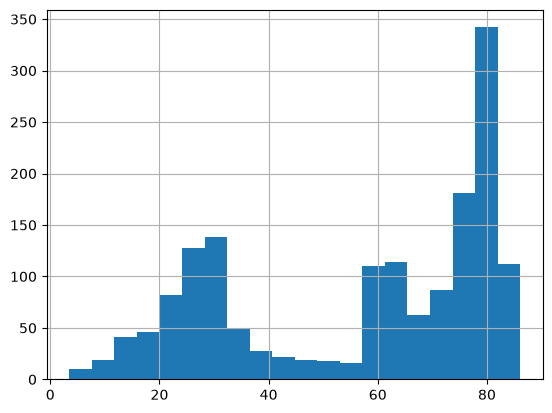

In [83]:
row_missing.hist(bins=20)

In [84]:
country_missing = (
    wide
    .drop(columns=["Year"])
    .groupby("Country Name")
    .apply(lambda x: x.isnull().mean().mean() * 100)
    .sort_values(ascending=False)
)

country_missing.head(20)

Country Name
Korea, Dem. People's Rep.    69.012934
South Sudan                  67.038802
Somalia, Fed. Rep.           62.791014
Eritrea                      61.334241
Liberia                      59.373724
Guinea-Bissau                59.346494
Afghanistan                  58.788291
Sudan                        58.679374
Yemen, Rep.                  57.971409
Sierra Leone                 57.222600
Congo, Dem. Rep.             57.154527
Syrian Arab Republic         56.528251
Gambia, The                  56.392103
Chad                         56.364874
Central African Republic     56.364874
Mozambique                   55.956433
Burundi                      55.942818
Uganda                       55.275698
Mali                         55.262083
Madagascar                   55.180395
dtype: float64

In [85]:
year_missing = (
    wide
    .drop(columns=["Country Name"])
    .groupby("Year")
    .apply(lambda x: x.isnull().mean().mean() * 100)
    .sort_values(ascending=False)
)

year_missing

Year
1961    84.389381
1960    84.000000
1962    83.893805
1963    83.716814
1964    83.469027
1966    83.150442
1967    83.044248
1968    82.938053
1965    82.654867
1969    82.619469
1972    80.955752
1971    80.743363
1973    80.637168
1974    80.601770
1970    80.530973
1976    80.460177
1977    80.212389
1979    80.000000
1978    79.929204
1975    79.433628
1980    78.477876
1982    77.592920
1983    77.451327
1981    77.026549
1984    76.814159
1985    73.769912
1986    73.628319
1988    73.203540
1989    73.097345
1987    72.849558
1994    63.752212
1991    63.610619
1990    63.575221
1993    62.761062
1998    62.690265
1996    62.477876
1999    61.911504
1992    61.840708
1995    61.840708
1997    61.840708
2024    60.637168
2023    41.805310
2022    36.530973
2002    33.380531
2001    33.345133
2003    32.070796
2007    30.619469
2004    29.663717
2005    29.451327
2008    29.274336
2021    29.238938
2009    28.035398
2012    28.000000
2016    27.575221
2011    27.504425
2020 

In [86]:
wide = wide[(wide["Year"] >= 2000) & (wide["Year"] <= 2022)].copy()

print(wide["Year"].min(), wide["Year"].max())
print(wide.shape)

2000 2022
(575, 115)


In [87]:
missing = wide.isnull().mean() * 100

missing_df = (
    missing.sort_values(ascending=False)
           .reset_index()
           .rename(columns={"index": "Variable", 0: "Missing (%)"})
)

missing_df.head(20)

,Series Name,Missing (%)
0,Women who were first married by age 18 (% of women ages 20-24),89.391304
1,Teenage mothers (% of women ages 15-19 who have had children or are currently pregnant),87.652174
2,Female headed households (% of households with a female head),87.304348
3,Consumption of iodized salt (% of households),84.000000
4,Maternal leave benefits (% of wages paid in covered period),83.304348
5,Unmet need for contraception (% of married women ages 15-49),82.782609
6,ARI treatment (% of children under 5 taken to a health provider),82.434783
7,"Literacy rate, adult total (% of people ages 15 and above)",82.260870
8,Diarrhea treatment (% of children under 5 receiving oral rehydration and continued feeding),82.086957
9,Pregnant women receiving prenatal care of at least four visits (% of pregnant women),81.913043


In [88]:
missing.describe()

count    115.000000
mean      27.151607
std       32.437775
min        0.000000
25%        0.000000
50%        9.565217
75%       63.043478
max       89.391304
dtype: float64

In [89]:
missing.sort_values(ascending=False).head(20)

Series Name
Women who were first married by age 18 (% of women ages 20-24)                                 89.391304
Teenage mothers (% of women ages 15-19 who have had children or are currently pregnant)        87.652174
Female headed households (% of households with a female head)                                  87.304348
Consumption of iodized salt (% of households)                                                  84.000000
Maternal leave benefits (% of wages paid in covered period)                                    83.304348
Unmet need for contraception (% of married women ages 15-49)                                   82.782609
ARI treatment (% of children under 5 taken to a health provider)                               82.434783
Literacy rate, adult total (% of people ages 15 and above)                                     82.260870
Diarrhea treatment (% of children under 5 receiving oral rehydration and continued feeding)    82.086957
Pregnant women receiving prenatal care of a

In [90]:
remove_vars = missing[missing > 80].index.tolist()

wide = wide.drop(columns=remove_vars)

print("Variables removed:", len(remove_vars))
print("Remaining variables:", wide.shape[1] - 2)   # exclude Country Name and Year

Variables removed: 13
Remaining variables: 100


In [91]:
missing = wide.isnull().mean() * 100

print(missing.describe())

count    102.000000
mean      19.948849
std       26.894418
min        0.000000
25%        0.000000
50%        5.913043
75%       39.391304
max       77.043478
dtype: float64


In [92]:
wide = wide.sort_values(["Country Name", "Year"])

cols = wide.columns.difference(["Country Name", "Year"])

wide[cols] = (
    wide.groupby("Country Name")[cols]
        .transform(lambda x: x.interpolate(method="linear", limit_direction="both"))
)

In [93]:
missing = wide.isnull().mean() * 100

missing.sort_values(ascending=False).head(20)

Series Name
People using safely managed drinking water services (% of population)                          48.0
Low-birthweight babies (% of births)                                                           44.0
Risk of catastrophic expenditure for surgical care (% of people at risk)                       32.0
People using safely managed sanitation services (% of population)                              32.0
Risk of impoverishing expenditure for surgical care (% of people at risk)                      32.0
Prevalence of current tobacco use (% of adults)                                                28.0
School enrollment, secondary (% net)                                                           16.0
Prevalence of undernourishment (% of population)                                               12.0
Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV)                12.0
School enrollment, primary (% net)                                                      

In [94]:
cols = wide.columns.difference(["Country Name", "Year"])

for col in cols:
    wide[col] = wide[col].fillna(wide[col].median())

In [95]:
wide.isnull().sum().sum()

np.int64(0)

In [96]:
wide.describe()

Series Name,Year,AIDS estimated deaths (UNAIDS estimates),"Adolescent fertility rate (births per 1,000 women ages 15-19)",Adults (ages 15+) and children (0-14 years) living with HIV,Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old","Age dependency ratio, young",Antiretroviral therapy coverage (% of people living with HIV),Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV),...,"Suicide mortality rate (per 100,000 population)","Total alcohol consumption per capita (liters of pure alcohol, projected estimates, 15+ years of age)",Treatment for hypertension (% of adults ages 30-79 with hypertension),"Tuberculosis case detection rate (%, all forms)","Tuberculosis death rate (per 100,000 people)",Tuberculosis treatment success rate (% of new cases),UHC service coverage index,"Unemployment, total (% of total labor force)",Urban population (% of total population),Vitamin A supplementation coverage rate (% of children ages 6-59 months)
count,575.000000,575.000000,575.000000,5.750000e+02,575.000000,575.000000,575.000000,575.000000,575.000000,575.000000,...,575.000000,575.000000,575.00000,575.000000,575.000000,575.000000,575.00000,575.000000,575.000000,575.000000
mean,2011.000000,11387.373913,111.853708,2.376311e+05,17029.408696,89.316095,5.649119,83.666977,21.453913,31.015652,...,6.698296,2.783511,19.68400,49.706261,42.638313,80.048696,33.22087,6.309664,32.890910,59.441739
std,6.639025,19554.316193,45.521017,4.319699e+05,33807.711360,13.132362,1.914015,14.511516,23.633988,31.663817,...,2.736927,3.277837,9.68602,14.957822,44.934416,9.594490,11.24522,4.968566,14.254652,35.132835
min,2000.000000,100.000000,0.525000,5.000000e+02,100.000000,42.945825,3.560025,27.320456,0.000000,0.000000,...,0.570000,0.000000,4.60000,9.800000,0.130000,40.000000,11.00000,0.316000,8.043814,0.000000
25%,2005.000000,1400.000000,81.326500,2.500000e+04,1600.000000,82.805493,4.798799,77.367665,1.000000,3.000000,...,4.820000,0.330000,12.65000,43.000000,16.000000,75.000000,24.60000,2.972000,21.597307,27.000000
50%,2011.000000,3700.000000,118.528000,8.000000e+04,4700.000000,91.190571,5.168304,86.247551,13.000000,19.000000,...,6.260000,1.795000,17.50000,50.000000,27.500000,82.000000,32.00000,4.255000,32.388318,70.000000
75%,2017.000000,9250.000000,145.268000,1.400000e+05,10000.000000,98.239711,5.845859,92.324570,34.000000,55.500000,...,8.450000,3.875000,24.50000,59.000000,54.000000,87.000000,41.00000,9.934000,40.409992,92.000000
max,2022.000000,91000.000000,206.357000,2.400000e+06,170000.000000,111.209538,16.708750,105.874708,90.000000,100.000000,...,14.260000,17.790000,45.60000,100.000000,540.000000,96.000000,73.00000,19.662000,76.000000,99.000000


In [97]:
wide[cols].skew().sort_values(ascending=False)

Series Name
Death rate, crude (per 1,000 people)                                                                     5.336422
Cause of death, by injury (% of total)                                                                   4.712156
Hospital beds (per 1,000 people)                                                                         4.587924
Population ages 65 and above (% of total population)                                                     4.216368
Physicians (per 1,000 people)                                                                            3.846406
Age dependency ratio, old                                                                                3.801224
Cause of death, by other COVID-19 pandemic-related outcomes (% of total)                                 3.699184
Tuberculosis death rate (per 100,000 people)                                                             3.518560
People using safely managed drinking water services (% of population)       

In [98]:
cols = wide.columns.difference(["Country Name", "Year"])

percent_cols = [c for c in cols if "%" in c]

len(percent_cols)

62

In [99]:
invalid_percent = []

for col in percent_cols:
    invalid = wide[(wide[col] < 0) | (wide[col] > 100)]

    if len(invalid) > 0:
        invalid_percent.append({
            "Variable": col,
            "Invalid values": len(invalid),
            "Minimum": wide[col].min(),
            "Maximum": wide[col].max()
        })

invalid_percent = pd.DataFrame(invalid_percent)

invalid_percent

,Variable,Invalid values,Minimum,Maximum
0,Age dependency ratio (% of working-age population),113,42.945825,111.209538
1,Population growth (annual %),13,-6.646408,6.157264
2,"Primary completion rate, total (% of relevant age group)",9,15.692990,105.759872


In [100]:
non_negative_cols = [
    c for c in cols
    if any(word in c.lower() for word in [
        "mortality",
        "death",
        "incidence",
        "prevalence",
        "population",
        "fertility",
        "hospital",
        "physician",
        "nurse",
        "bed",
        "expenditure",
        "coverage",
        "immunization",
        "malaria",
        "tuberculosis",
        "hiv",
        "birth",
        "stunting",
        "wasting",
        "underweight",
        "overweight",
        "anemia",
        "life expectancy"
    ])
]

In [101]:
negative_values = []

for col in non_negative_cols:
    n = (wide[col] < 0).sum()

    if n > 0:
        negative_values.append({
            "Variable": col,
            "Negative values": n,
            "Minimum": wide[col].min()
        })

negative_values = pd.DataFrame(negative_values)

negative_values

,Variable,Negative values,Minimum
0,Population growth (annual %),13,-6.646408


In [102]:
duplicates = wide.duplicated(
    subset=["Country Name", "Year"]
).sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [103]:
wide.isna().sum().sum()

np.int64(0)

In [104]:
constant = wide.nunique()

constant = constant[constant == 1]

constant

Series([], dtype: int64)

In [105]:
wide.to_csv(
    r"C:\Users\786\Desktop\document\Global Health Policy Decision Intelligence\notebooks\clean_model_data.csv",
    index=False
)

In [106]:
import numpy as np

# correlation matrix
corr = wide.drop(columns=["Country Name", "Year"]).corr()

In [107]:
import numpy as np

numeric = wide.select_dtypes(include="number")

corr = numeric.corr()

In [108]:
corr.shape

(101, 101)

In [109]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

to_drop = [column for column in upper.columns if any(upper[column].abs() > 0.90)]

print("Number of highly correlated variables:", len(to_drop))

Number of highly correlated variables: 24


In [110]:
to_drop

['Adults (ages 15+) and children (ages 0-14) newly infected with HIV',
 'Age dependency ratio, young',
 'Cause of death, by non-communicable diseases (% of total)',
 'Children orphaned by HIV/AIDS',
 'Fertility rate, total (births per woman)',
 'Immunization, Pol3 (% of one-year-old children)',
 'Immunization, measles (% of children ages 12-23 months)',
 'Maternal mortality ratio (modeled estimate, per 100,000 live births)',
 'Mortality rate, infant (per 1,000 live births)',
 'Mortality rate, under-5 (per 1,000)',
 'Number of maternal deaths',
 'Number of neonatal deaths',
 'Number of stillbirths',
 'Number of under-five deaths',
 'Out-of-pocket expenditure (% of current health expenditure)',
 'Physicians (per 1,000 people)',
 'Population ages 0-14 (% of total population)',
 'Population ages 15-64 (% of total population)',
 'Population ages 65 and above (% of total population)',
 'Population, total',
 'Prevalence of HIV, total (% of population ages 15-49)',
 'Prevalence of anemia among

In [111]:
remove_corr = [
    "Age dependency ratio, young",
    "Population ages 15-64 (% of total population)",
    "Immunization, Pol3 (% of one-year-old children)",
    "Immunization, measles (% of children ages 12-23 months)",
    "Number of maternal deaths",
    "Number of neonatal deaths",
    "Number of under-five deaths",
    "Number of stillbirths"
]

In [112]:
wide = wide.drop(columns=remove_corr)

In [113]:
wide.to_csv("../data/clean/health_data_clean.csv",index=False)

In [114]:
print("Rows:", wide.shape[0])
print("Columns:", wide.shape[1])
print("Countries:", wide["Country Name"].nunique())
print("Years:", wide["Year"].nunique())

Rows: 575
Columns: 94
Countries: 25
Years: 23


In [115]:
wide.columns.tolist()

['Country Name',
 'Year',
 'AIDS estimated deaths (UNAIDS estimates)',
 'Adolescent fertility rate (births per 1,000 women ages 15-19)',
 'Adults (ages 15+) and children (0-14 years) living with HIV',
 'Adults (ages 15+) and children (ages 0-14) newly infected with HIV',
 'Age dependency ratio (% of working-age population)',
 'Age dependency ratio, old',
 'Antiretroviral therapy coverage (% of people living with HIV)',
 'Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV)',
 'Births attended by skilled health staff (% of total)',
 'Cause of death, by communicable diseases and maternal, prenatal and nutrition conditions (% of total)',
 'Cause of death, by injury (% of total)',
 'Cause of death, by non-communicable diseases (% of total)',
 'Cause of death, by other COVID-19 pandemic-related outcomes (% of total)',
 'Children orphaned by HIV/AIDS',
 'Current health expenditure (% of GDP)',
 'Current health expenditure per capita (current US$)',
 'Current health